# Emotion Classification with RNNs, LSTMs & GRUs

Classifying short texts into 6 emotions (**sadness, joy, love, anger, fear, surprise**) using the `dair-ai/emotion` dataset.

**Approach**
1. A classical baseline: TF-IDF + Logistic Regression
2. Plain Simple RNN, LSTM and GRU
3. An advanced stacked Bidirectional GRU

All model selection is done on the **validation split**. The **test split** is only used for the final numbers.

## 1. Import Libraries

In [1]:
import os
import json
import random
import pickle

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from datasets import load_dataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

pd.set_option('display.max_colwidth', 120)

## 2. Load Dataset
Load `dair-ai/emotion` from Hugging Face: https://huggingface.co/datasets/dair-ai/emotion

The dataset ships with separate **train / validation / test** splits, and we use all three.

In [2]:
emotion_dataset = load_dataset('dair-ai/emotion')
label_names = emotion_dataset['train'].features['label'].names
print(label_names)

train_text, y_train = emotion_dataset['train']['text'],      np.array(emotion_dataset['train']['label'])
val_text,   y_val   = emotion_dataset['validation']['text'], np.array(emotion_dataset['validation']['label'])
test_text,  y_test  = emotion_dataset['test']['text'],       np.array(emotion_dataset['test']['label'])

print(f'Train: {len(train_text)} | Validation: {len(val_text)} | Test: {len(test_text)}')

README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

split/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']
Train: 16000 | Validation: 2000 | Test: 2000


In [3]:
def to_df(texts, labels):
    return pd.DataFrame({'text': texts, 'label': [label_names[i] for i in labels]})

df_train = to_df(train_text, y_train)
df_val   = to_df(val_text, y_val)
df_test  = to_df(test_text, y_test)

df_train.isnull().sum()

,0
text,0
label,0


## 3. Exploratory Data Analysis (EDA)
Class distribution and sentence lengths (the length check is used to justify the padding length).

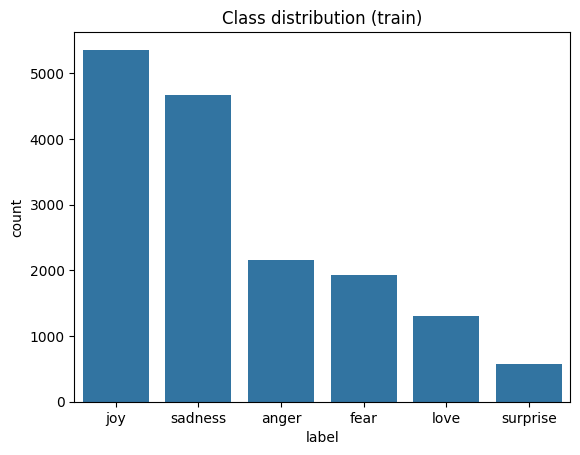

,proportion
label,
joy,0.335
sadness,0.292
anger,0.135
fear,0.121
love,0.082
surprise,0.036


In [4]:
order = df_train['label'].value_counts().index
sns.countplot(x='label', data=df_train, order=order)
plt.title('Class distribution (train)')
plt.show()

df_train['label'].value_counts(normalize=True).round(3)

count    16000.000000
mean        19.166313
std         10.986905
min          2.000000
25%         11.000000
50%         17.000000
75%         25.000000
max         66.000000
Name: text, dtype: float64
Sentences with <= 50 words: 98.67%


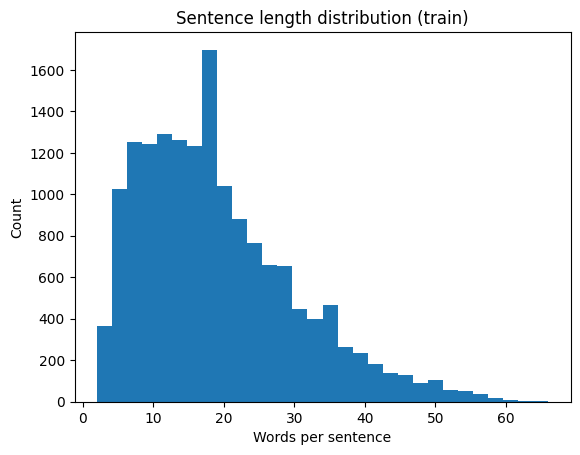

In [5]:
word_counts = df_train['text'].str.split().str.len()
print(word_counts.describe())
print(f'Sentences with <= 50 words: {(word_counts <= 50).mean():.2%}')

plt.hist(word_counts, bins=30)
plt.xlabel('Words per sentence')
plt.ylabel('Count')
plt.title('Sentence length distribution (train)')
plt.show()

## 4. Data Preprocessing
Tokenize (fit on the **training set only**), then pad every sentence to length 50.

> **Note on padding:** the embedding layers use `mask_zero=True`, so the recurrent layers ignore the padding tokens.
> Without masking, a unidirectional RNN reads the real words and then dozens of padding tokens, so its final state is mostly noise and training can stall at chance level.

In [6]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

MAX_WORDS = 10000
MAX_LEN = 50

tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token='<unk>')
tokenizer.fit_on_texts(df_train['text'])

def encode(texts):
    seqs = tokenizer.texts_to_sequences(texts)
    return pad_sequences(seqs, maxlen=MAX_LEN, padding='post', truncating='post')

X_train = encode(df_train['text'])
X_val   = encode(df_val['text'])
X_test  = encode(df_test['text'])

num_classes = len(np.unique(y_train))

print(f'Vocabulary size: {len(tokenizer.word_index)} (using top {MAX_WORDS})')
print(f'X_train: {X_train.shape} | X_val: {X_val.shape} | X_test: {X_test.shape}')
print(f'Number of classes: {num_classes}')

Vocabulary size: 15213 (using top 10000)
X_train: (16000, 50) | X_val: (2000, 50) | X_test: (2000, 50)
Number of classes: 6


## 5. Shared Training Utilities
Balanced class weights for the skewed classes, plus helper functions so that every model is trained and evaluated in exactly the same way.

In [7]:
import tensorflow as tf
from sklearn.utils import class_weight
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from tensorflow.keras.callbacks import EarlyStopping

tf.random.set_seed(SEED)

class_weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weight_dict = dict(enumerate(class_weights))
class_weight_dict

{0: np.float64(0.5715102157451064),
 1: np.float64(0.49732686808404825),
 2: np.float64(2.044989775051125),
 3: np.float64(1.2351397251814111),
 4: np.float64(1.3766993632765445),
 5: np.float64(4.662004662004662)}

In [9]:
histories = {}        # training curves for every model
trained_models = {}   # trained Keras models
results = []          # one row per model for the final comparison table


def train_model(model, name, epochs=20, batch_size=32):
    """Compile and train a model. Early stopping watches the VALIDATION loss."""
    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=batch_size,
        class_weight=class_weight_dict,
        callbacks=[early_stopping]
    )
    histories[name] = history.history
    trained_models[name] = model


def log_result(name, val_pred, test_pred):
    row = {
        'Model': name,
        'Val Accuracy': accuracy_score(y_val, val_pred),
        'Test Accuracy': accuracy_score(y_test, test_pred),
        'Test Macro-F1': f1_score(y_test, test_pred, average='macro'),
    }
    results.append(row)
    print(f"{name}: val acc = {row['Val Accuracy']:.4f} | test acc = {row['Test Accuracy']:.4f} | test macro-F1 = {row['Test Macro-F1']:.4f}")


def evaluate_keras(name):
    model = trained_models[name]
    val_pred  = np.argmax(model.predict(X_val,  verbose=0), axis=1)
    test_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)
    log_result(name, val_pred, test_pred)

## 6. Baseline: TF-IDF + Logistic Regression
A classical reference point. If a deep model can't beat this, it isn't worth the extra complexity.

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

baseline = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2), min_df=2),
    LogisticRegression(max_iter=1000, class_weight='balanced')
)
baseline.fit(df_train['text'], y_train)

log_result(
    'TF-IDF + LogReg',
    baseline.predict(df_val['text']),
    baseline.predict(df_test['text'])
)

TF-IDF + LogReg: val acc = 0.8720 | test acc = 0.8685 | test macro-F1 = 0.8342


## 7. Phase 1: Plain Foundational Models
Simple RNN, LSTM and GRU, all with the same layout (two stacked recurrent layers, dropout 0.5).

### 7.1 Model 1: Simple RNN

In [11]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, SimpleRNN, LSTM, GRU, Bidirectional, Dense, Dropout

rnn_model = Sequential([
    Input(shape=(MAX_LEN,)),
    Embedding(input_dim=MAX_WORDS, output_dim=128, mask_zero=True),
    SimpleRNN(units=128, return_sequences=True),
    Dropout(0.5),
    SimpleRNN(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax')
])

train_model(rnn_model, 'RNN')
evaluate_keras('RNN')

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 14s 16ms/step - accuracy: 0.1910 - loss: 1.8775 - val_accuracy: 0.3715 - val_loss: 1.5954
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.5276 - loss: 1.2163 - val_accuracy: 0.6700 - val_loss: 0.8948
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.7517 - loss: 0.6798 - val_accuracy: 0.7535 - val_loss: 0.7702
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.8001 - loss: 0.5556 - val_accuracy: 0.7695 - val_loss: 0.7710
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.8126 - loss: 0.5023 - val_accuracy: 0.7895 - val_loss: 0.7466
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.8436 - loss: 0.4318 - val_accuracy: 0.5320 - val_loss: 1.9324
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.7637 - loss: 0.5648 - val_accuracy: 0.7440 - val_loss: 0.7961
Epoch 8/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.8760 - loss: 0.3343 - val_acc

### 7.2 Model 2: Standard LSTM

In [12]:
lstm_model = Sequential([
    Input(shape=(MAX_LEN,)),
    Embedding(input_dim=MAX_WORDS, output_dim=128, mask_zero=True),
    LSTM(units=128, return_sequences=True),
    Dropout(0.5),
    LSTM(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax')
])

train_model(lstm_model, 'LSTM')
evaluate_keras('LSTM')

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 12s 11ms/step - accuracy: 0.5490 - loss: 1.1582 - val_accuracy: 0.8215 - val_loss: 0.5702
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.8871 - loss: 0.3815 - val_accuracy: 0.9000 - val_loss: 0.3217
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9304 - loss: 0.2197 - val_accuracy: 0.9075 - val_loss: 0.2948
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.9456 - loss: 0.1596 - val_accuracy: 0.9110 - val_loss: 0.2878
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9591 - loss: 0.1222 - val_accuracy: 0.9175 - val_loss: 0.2840
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9596 - loss: 0.1151 - val_accuracy: 0.9055 - val_loss: 0.3515
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9714 - loss: 0.0848 - val_accuracy: 0.9105 - val_loss: 0.3587
Epoch 8/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9774 - loss: 0.0673 - val_acc

### 7.3 Model 3: Standard GRU

In [13]:
gru_model = Sequential([
    Input(shape=(MAX_LEN,)),
    Embedding(input_dim=MAX_WORDS, output_dim=128, mask_zero=True),
    GRU(units=128, return_sequences=True),
    Dropout(0.5),
    GRU(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax')
])

train_model(gru_model, 'GRU')
evaluate_keras('GRU')

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.5605 - loss: 1.0899 - val_accuracy: 0.9065 - val_loss: 0.3219
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9215 - loss: 0.2247 - val_accuracy: 0.9210 - val_loss: 0.2482
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9451 - loss: 0.1494 - val_accuracy: 0.9245 - val_loss: 0.2524
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9596 - loss: 0.1112 - val_accuracy: 0.9120 - val_loss: 0.3073
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9662 - loss: 0.0959 - val_accuracy: 0.9260 - val_loss: 0.2929
GRU: val acc = 0.9210 | test acc = 0.9105 | test macro-F1 = 0.8768


## 8. Phase 2: Advanced Bidirectional GRU
The GRU is made bidirectional and the embedding is widened to 300 dimensions. The output layer has `num_classes` (= 6) units with softmax, so the model returns one probability per emotion and the largest one is the prediction.

In [14]:
BiGRU = Sequential([
    Input(shape=(MAX_LEN,)),
    Embedding(input_dim=MAX_WORDS, output_dim=300, mask_zero=True),
    Bidirectional(GRU(128, return_sequences=True)),
    Dropout(0.5),
    Bidirectional(GRU(64)),
    Dropout(0.5),
    Dense(num_classes, activation='softmax')
])

BiGRU.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 50, 300)        │     3,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 50, 256)        │       330,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 50, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 128)            │       123,648 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,454,662 (13.18 MB)

 Trainable params: 3,454,662 (13.18 MB)

 Non-trainable params: 0 (0.00 B)

In [15]:
train_model(BiGRU, 'BiGRU')
evaluate_keras('BiGRU')

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 12s 18ms/step - accuracy: 0.6479 - loss: 0.8958 - val_accuracy: 0.9085 - val_loss: 0.2933
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - accuracy: 0.9337 - loss: 0.1804 - val_accuracy: 0.9260 - val_loss: 0.2138
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 10s 20ms/step - accuracy: 0.9549 - loss: 0.1172 - val_accuracy: 0.9235 - val_loss: 0.2904
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - accuracy: 0.9672 - loss: 0.0856 - val_accuracy: 0.9300 - val_loss: 0.2383
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - accuracy: 0.9775 - loss: 0.0651 - val_accuracy: 0.9170 - val_loss: 0.2946
BiGRU: val acc = 0.9260 | test acc = 0.9175 | test macro-F1 = 0.8784


## 9. Model Comparison
Models are ranked by **validation** accuracy. Test numbers are shown for reporting only.

In [16]:
results_df = pd.DataFrame(results).sort_values(by='Val Accuracy', ascending=False).reset_index(drop=True)
results_df

,Model,Val Accuracy,Test Accuracy,Test Macro-F1
0,BiGRU,0.9260,0.9175,0.878439
1,GRU,0.9210,0.9105,0.876755
2,LSTM,0.9175,0.9165,0.878936
3,TF-IDF + LogReg,0.8720,0.8685,0.834227
4,RNN,0.8200,0.8260,0.755625


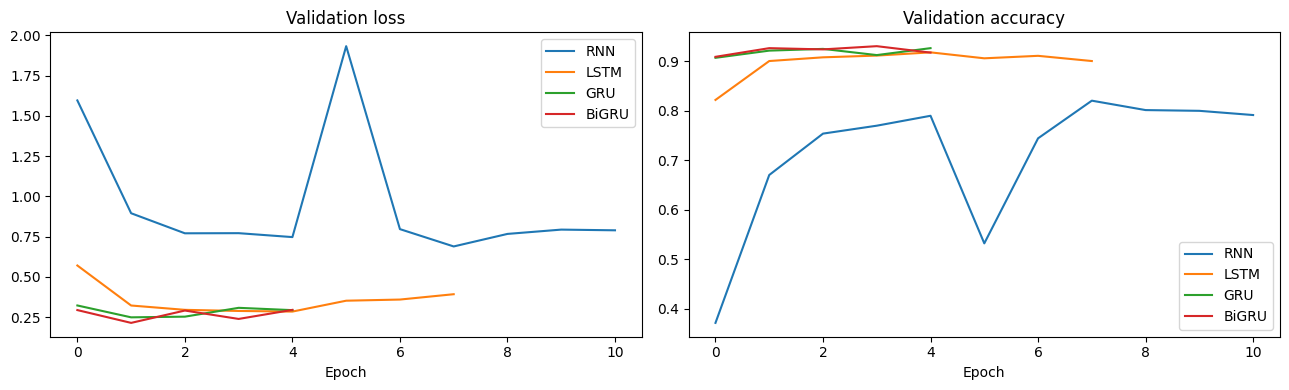

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for name, h in histories.items():
    axes[0].plot(h['val_loss'], label=name)
    axes[1].plot(h['val_accuracy'], label=name)

axes[0].set_title('Validation loss')
axes[1].set_title('Validation accuracy')
for ax in axes:
    ax.set_xlabel('Epoch')
    ax.legend()

plt.tight_layout()
plt.show()

## 10. Final Model Evaluation & Error Analysis
The best deep model (by validation accuracy) is evaluated in detail on the test set.

In [18]:
deep_results = results_df[results_df['Model'] != 'TF-IDF + LogReg']
best_name = deep_results.iloc[0]['Model']
best_model = trained_models[best_name]
print(f'Best deep model: {best_name}')

best_test_pred = np.argmax(best_model.predict(X_test, verbose=0), axis=1)

print(classification_report(y_test, best_test_pred, target_names=label_names, digits=3))

Best deep model: BiGRU
              precision    recall  f1-score   support

     sadness      0.975     0.940     0.957       581
         joy      0.962     0.914     0.937       695
        love      0.767     0.912     0.833       159
       anger      0.915     0.945     0.930       275
        fear      0.934     0.821     0.874       224
    surprise      0.591     0.985     0.739        66

    accuracy                          0.917      2000
   macro avg      0.857     0.920     0.878      2000
weighted avg      0.929     0.917     0.920      2000



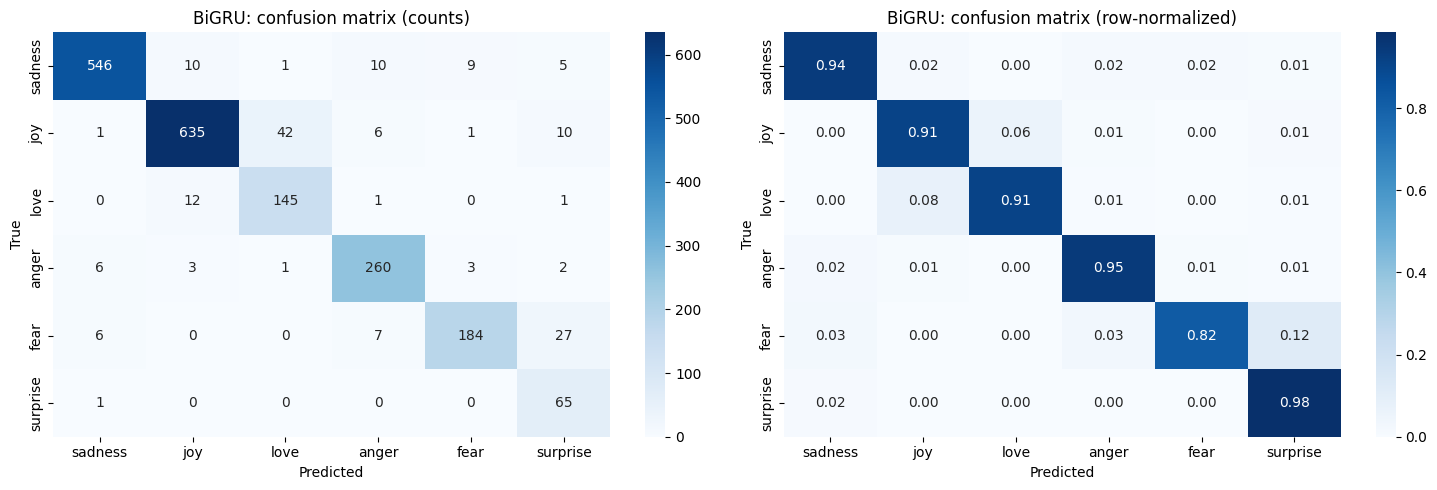

In [19]:
cm = confusion_matrix(y_test, best_test_pred)
cm_norm = confusion_matrix(y_test, best_test_pred, normalize='true')

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_names, yticklabels=label_names, ax=axes[0])
axes[0].set_title(f'{best_name}: confusion matrix (counts)')

sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=label_names, yticklabels=label_names, ax=axes[1])
axes[1].set_title(f'{best_name}: confusion matrix (row-normalized)')

for ax in axes:
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')

plt.tight_layout()
plt.show()

In [20]:
# Look at actual mistakes
test_eval = df_test.copy()
test_eval['predicted'] = [label_names[i] for i in best_test_pred]
wrong = test_eval[test_eval['label'] != test_eval['predicted']]

print(f'Misclassified: {len(wrong)} / {len(test_eval)}')
wrong.sample(10, random_state=SEED)

Misclassified: 165 / 2000


,text,label,predicted
1605,i feel like everythings going to happen with out me and that ive been disillusioned this whole time,sadness,surprise
1417,i don t know about you but i m feeling amp blessed,joy,love
1583,i am not feeling so generous and he is sent to the sofa where he glares at me for the next six hours,joy,love
591,i feel inside this life is like a game sometimes then you came around me the walls just dissapeared nothing to surro...,sadness,joy
1150,when i heard the last regulation of the socialist govrenment concerning pensions,sadness,anger
376,i suppose if one was feeling generous one could say i was stressed by the elevator ride,joy,love
1894,i am not sure how i feel i think because i felt like i already knew i have already sort of accepted it,joy,love
575,i feel not having a generous spirit or a forgiving nature closes me off from accepting gifts from the universe,love,joy
1296,i that it feels like she is being tortured,fear,anger
1725,i feel like it add a little bit more shield from the cold and the fabric is great for wicking away sweat,anger,joy


### Observations
Model is confused between Love and Joy mostly.

## 11. Final Predictions
Try the best model on new sentences. The first five are written in a different style from the training data (which is mostly "i feel ..." statements), so they are a harder test of generalization.

In [21]:
def predict_emotion(texts, model=None):
    """Return (emotion, confidence) for each input text."""
    if model is None:
        model = best_model
    probs = model.predict(encode(texts), verbose=0)
    return [(label_names[i], float(p[i])) for i, p in zip(probs.argmax(axis=1), probs)]


sample_texts = [
    "I can't believe how happy I am right now, this is amazing!",
    "I feel so alone and hopeless today.",
    "I am furious that they cancelled the trip at the last minute.",
    "I feel terrified when walking down dark alleyways alone.",
    "I was shocked and completely surprised by the unexpected gift!",
    "i feel so grateful for everything my family has done for me",
    "i feel really annoyed with how people treat me at work",
]

for text, (emotion, conf) in zip(sample_texts, predict_emotion(sample_texts)):
    print(f'Text: {text}\nPredicted: {emotion} ({conf:.0%})\n')

Text: I can't believe how happy I am right now, this is amazing!
Predicted: surprise (90%)

Text: I feel so alone and hopeless today.
Predicted: sadness (100%)

Text: I am furious that they cancelled the trip at the last minute.
Predicted: anger (100%)

Text: I feel terrified when walking down dark alleyways alone.
Predicted: fear (100%)

Text: I was shocked and completely surprised by the unexpected gift!
Predicted: surprise (100%)

Text: i feel so grateful for everything my family has done for me
Predicted: joy (93%)

Text: i feel really annoyed with how people treat me at work
Predicted: anger (100%)



## 12. Save Model & Tokenizer
Export everything needed to serve the model (for example from a Streamlit app or an API).

In [22]:
model_dir = 'Artifacts'
os.makedirs(model_dir, exist_ok=True)

best_model.save(os.path.join(model_dir, 'emotion_model.keras'))

with open(os.path.join(model_dir, 'tokenizer.pkl'), 'wb') as f:
    pickle.dump(tokenizer, f)

with open(os.path.join(model_dir, 'config.json'), 'w') as f:
    json.dump({'max_len': MAX_LEN, 'label_names': label_names, 'model': best_name}, f, indent=2)

os.listdir(model_dir)

['emotion_model.keras', 'config.json', 'tokenizer.pkl']